# Étude de cas 5 — Jalon 2 : Écouter les vibrations
**Plan** : 0. Préparation · Q1 CNN + règle d'étiquetage · Q2 exactitude selon la RUL · Q3 auto-encodeur (indicateur de santé) · Q4 apport au MLP de RUL · Vérifications théoriques · Page de décisions.

**Protocole** : tous les réglages se font sur la **validation** (découpage par pompe). Le **test** n'est utilisé qu'une fois, à la toute fin (section *Test*, drapeau `EVAL_TEST`).

## 0. Préparation

In [27]:
import platform, sklearn, scipy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from pathlib import Path
Path("figures").mkdir(exist_ok=True); Path("models").mkdir(exist_ok=True)
def sauver_fig(nom):
    plt.savefig(f"figures/{nom}.png", dpi=150, bbox_inches="tight")
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupKFold
from scipy.stats import spearmanr

SEED = 42
RUL_MAX = 125        # plafond de la RUL (cahier des charges)
SEUIL_EVAL = 60      # zone d'évaluation du mode (cahier des charges)
EVAL_TEST = True    # passer à True UNE seule fois, à la fin du jalon
tf.keras.utils.set_random_seed(SEED)

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| tensorflow", tf.__version__, "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

A = np.load("data/uc5_flotteA.npz")
CAPTEURS = [f"c{i}" for i in range(8)]     # remplacer par les vrais noms si connus
NOMS = ["sain", "roulement", "désalignement", "cavitation"]

# Journal d'expériences (point d'appel unique : adapter ici à `journaliser` du notebook de démarrage)
JOURNAL = []
def log(question, essai, **resultats):
    JOURNAL.append(dict(jalon=2, question=question, essai=essai, **resultats))

python 3.11.16 | numpy 2.4.6 | pandas 3.0.5 | tensorflow 2.21.0 | sklearn 1.9.1 | scipy 1.17.1


**Données.** Spectrogrammes dans [0, 1] ; capteurs normalisés **par régime de charge** avec les statistiques des cycles sains du train (RUL > 150) ; la charge est mise à l'échelle `(charge − 80)/20` pour avoir un ordre de grandeur comparable aux capteurs.

In [28]:
SPEC = {s: A["spectro_" + s][..., None].astype("float32") / 255.0 for s in ["train", "val", "test"]}

def vers_df(s):
    d = pd.DataFrame(A["capteurs_" + s], columns=CAPTEURS)
    d["pompe"], d["cycle"], d["charge"] = A["pompe_" + s], A["cycle_" + s], A["charge_" + s]
    if "rul_" + s in A.files:
        d["rul"], d["mode"] = A["rul_" + s], A["mode_" + s]
    return d

TA = {s: vers_df(s) for s in ["train", "val", "test"]}
for s in TA:   # les spectrogrammes restent alignés avec les tableaux seulement si l'ordre est (pompe, cycle)
    assert TA[s].sort_values(["pompe", "cycle"]).index.equals(TA[s].index)

sain_tr = TA["train"][TA["train"].rul > 150]
mu, sd = sain_tr.groupby("charge")[CAPTEURS].mean(), sain_tr.groupby("charge")[CAPTEURS].std()

def normaliser(df):
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS].values - mu.loc[df.charge].values) / sd.loc[df.charge].values
    out["charge"] = (df.charge - 80) / 20
    return out

NA = {s: normaliser(TA[s]) for s in TA}
FEAT = CAPTEURS + ["charge"]
print({s: len(TA[s]) for s in TA}, "| régimes :", list(mu.index))

{'train': 19220, 'val': 4170, 'test': 6538} | régimes : [0.6000000238418579, 0.800000011920929, 1.0]


## Q1. CNN de classification + règle d'étiquetage

**Étiquettes** : `0` sain, `1` roulement, `2` désalignement, `3` cavitation. Règle : *sain si RUL > seuil, sinon 1 + mode*.

**Pourquoi le seuil compte.** Loin de la panne, le spectrogramme d'un cycle « futur défaillant » est identique à un cycle sain. Un seuil trop grand impose au CNN de distinguer des images identiques (bruit d'étiquette). Un seuil inférieur à 60 ne montre jamais de défaut dans une partie de la zone évaluée (RUL ≤ 60), donc ces cycles seront classés « sain ».

**Architecture** : 2 blocs `Conv 3×3 → MaxPool 2×2` (16 puis 32 filtres), `Flatten` (la ligne = une fréquence précise, la position verticale est utile, donc pas de pooling global), `Dropout`, `Dense(64)`, `Dense(4, softmax)`. Déséquilibre de classes compensé par `class_weight`.

**Mesure** (seule métrique du sujet) : `acc_60` = exactitude du mode sur les cycles de validation à RUL ≤ 60 (vérité fixe `1 + mode`, donc comparable entre seuils). Chaque seuil est répété sur 2 graines.

In [29]:
def etiquette_mode(s, seuil=60):
    return np.where(A["rul_" + s] > seuil, 0, 1 + A["mode_" + s]).astype("int32")

def construire_cnn():
    m = keras.Sequential([
        layers.Input((32, 32, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.Flatten(), layers.Dropout(0.3),
        layers.Dense(64, activation="relu"), layers.Dense(4, activation="softmax")])
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrainer_cnn(seuil, seed, idx=None, epochs=12):
    tf.keras.utils.set_random_seed(seed)
    X, y = SPEC["train"], etiquette_mode("train", seuil)
    if idx is not None:
        X, y = X[idx], y[idx]
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(4), y=y)))
    m = construire_cnn()
    m.fit(X, y, validation_data=(SPEC["val"], etiquette_mode("val", seuil)),
          epochs=epochs, batch_size=64, class_weight=cw, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    return m

def acc_60(m):
    pred = m.predict(SPEC["val"], verbose=0).argmax(1)
    p = A["rul_val"] <= SEUIL_EVAL #[False False False ...  True  True  True]
    return float((pred[p] == 1 + A["mode_val"][p]).mean())

        mean    std
seuil              
30     0.687  0.009
60     0.875  0.014
90     0.894  0.014
125    0.920  0.005

meilleur seuil : 125 | seuil retenu : 125


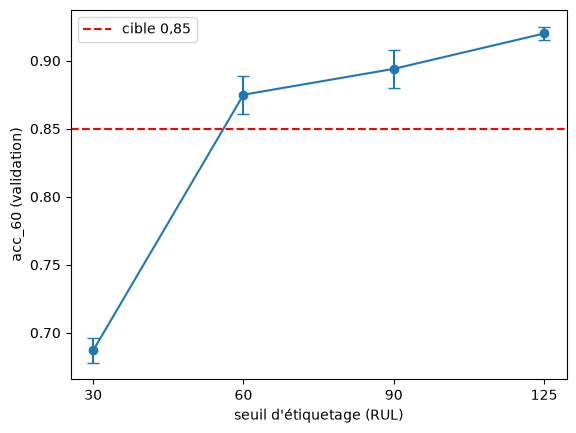

In [30]:
SEUILS = [30, 60, 90, 125]
rows = []
for seuil in SEUILS:
    for seed in (0,1):
        a = acc_60(entrainer_cnn(seuil, seed))
        rows.append(dict(seuil=seuil, seed=seed, acc_60=a))
        log("Q1", f"cnn_seuil{seuil}_seed{seed}", seuil=seuil, seed=seed, acc_60=round(a, 4))

res1 = pd.DataFrame(rows)
tab1 = res1.groupby("seuil").acc_60.agg(["mean", "std"]).round(3)
print(tab1)

# Règle de choix : le plus petit seuil dont la moyenne est à moins d'un écart-type du meilleur
best = tab1["mean"].idxmax()
SEUIL_RETENU = min(s for s in tab1.index if tab1.loc[s, "mean"] >= tab1.loc[best, "mean"] - tab1.loc[best, "std"])
print(f"\nmeilleur seuil : {best} | seuil retenu : {SEUIL_RETENU}")

plt.errorbar(tab1.index.astype(str), tab1["mean"], yerr=tab1["std"], marker="o", capsize=4)
plt.axhline(0.85, color="r", ls="--", label="cible 0,85")
plt.xlabel("seuil d'étiquetage (RUL)"); plt.ylabel("acc_60 (validation)")
plt.legend()
sauver_fig("q1_seuil_etiquetage"); plt.show()

In [31]:
t = tab1
print(f"Seuil 30 : acc_60 = {t.loc[30,'mean']:.3f} (inférieur à 60 -> le CNN ne voit jamais de défaut entre RUL 31 et 60).")
print(f"Seuils 60 à 125 : {t.loc[60,'mean']:.3f} -> {t.loc[125,'mean']:.3f} (écarts à comparer à l'écart-type {t.loc[60:125,'std'].max():.3f}).")
print(f"Retenu : {SEUIL_RETENU}  (le plus petit seuil statistiquement équivalent au meilleur : moins de bruit d'étiquette).")
cnn = entrainer_cnn(SEUIL_RETENU, SEED)           # modèle retenu, graine fixée
cnn.save("models/jalon2_cnn_retenu.keras")
print("acc_60 du modèle retenu (validation) :", round(acc_60(cnn), 3), "| cible finale : 0,85")

Seuil 30 : acc_60 = 0.687 (inférieur à 60 -> le CNN ne voit jamais de défaut entre RUL 31 et 60).
Seuils 60 à 125 : 0.875 -> 0.920 (écarts à comparer à l'écart-type 0.014).
Retenu : 125  (le plus petit seuil statistiquement équivalent au meilleur : moins de bruit d'étiquette).
acc_60 du modèle retenu (validation) : 0.906 | cible finale : 0,85


## Q2. Exactitude en fonction de la RUL

Par tranche de RUL (< 60), on sépare deux erreurs différentes : **détecté** (le CNN répond autre chose que « sain ») et **bon mode parmi les détectés** (confusion entre modes). L'exactitude est le produit des deux ; cela montre si le problème est la *visibilité* du défaut ou la *confusion* entre défauts.

tranche   n  exactitude  detecte  bon_mode_si_detecte
   0-10 150       1.000    1.000                  1.0
  10-20 150       1.000    1.000                  1.0
  20-30 150       1.000    1.000                  1.0
  30-40 150       0.993    0.993                  1.0
  40-50 150       0.800    0.800                  1.0
  50-60 150       0.680    0.680                  1.0


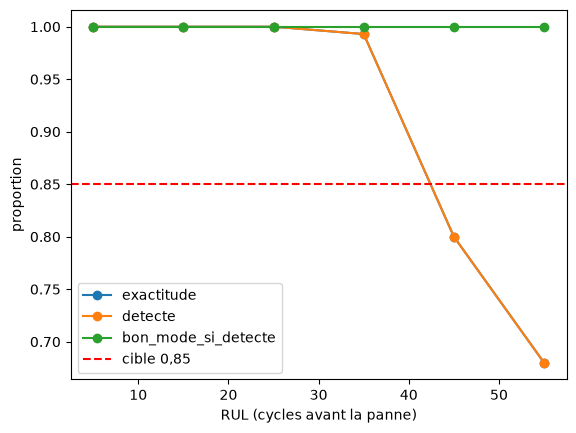


Mode reconnaissable (exactitude >= 0,85) pour RUL < 40 cycles.
Moyenne sur RUL <= 60 : 0.906


In [32]:
pred = cnn.predict(SPEC["val"], verbose=0).argmax(1)
rul, vrai = A["rul_val"], 1 + A["mode_val"]
bornes = [0, 10, 20, 30, 40, 50, 60]
rows = []
for a, b in zip(bornes[:-1], bornes[1:]):
    m = (rul >= a) & (rul < b)
    p, v = pred[m], vrai[m]
    det = p != 0
    rows.append(dict(tranche=f"{a}-{b}", n=int(m.sum()), exactitude=(p == v).mean(),
                     detecte=det.mean(), bon_mode_si_detecte=(p[det] == v[det]).mean() if det.any() else np.nan))
q2 = pd.DataFrame(rows).round(3)
print(q2.to_string(index=False))

x = [(a + b) / 2 for a, b in zip(bornes[:-1], bornes[1:])]
for col in ["exactitude", "detecte", "bon_mode_si_detecte"]:
    plt.plot(x, q2[col], marker="o", label=col)
plt.axhline(0.85, color="r", ls="--", label="cible 0,85")
plt.xlabel("RUL (cycles avant la panne)"); plt.ylabel("proportion")
plt.legend()
sauver_fig("q2_exactitude_par_rul"); plt.show()

ok = (q2.exactitude >= 0.85).values
i = 0
while i < len(ok) and ok[i]:
    i += 1
log("Q2", "exactitude_par_tranche", seuil=SEUIL_RETENU, borne_fiable=bornes[i])
print(f"\nMode reconnaissable (exactitude >= 0,85) pour RUL < {bornes[i]} cycles.")
print("Moyenne sur RUL <= 60 :", round(acc_60(cnn), 3))

**Lecture.** Si « détecté » chute dans les tranches 40-60 alors que « bon mode » reste élevé, le défaut est simplement **pas encore visible** dans le spectrogramme (limite physique), pas confondu avec un autre mode. Cette limite de visibilité justifie aussi le choix du seuil d'étiquetage de la Q1.

## Q3. Auto-encodeur sur fenêtres de cycles sains → indicateur de santé

**Idée.** L'auto-encodeur n'apprend que le « normal » (fenêtres dont le dernier cycle a RUL > 150). Quand la pompe se dégrade, il reconstruit mal : l'**erreur de reconstruction** sert d'indicateur de santé, sans aucune étiquette de panne.

**Mesures** : corrélation de rang (Spearman) avec la RUL (négative attendue : erreur ↑ quand RUL ↓) et **délai de détection** = RUL au moment où l'erreur dépasse le seuil (99ᵉ percentile des erreurs saines du train) pendant 3 cycles de suite. Un délai grand = détection précoce. On compare des fenêtres de k ∈ {1, 5, 15} cycles.

In [33]:
def fenetres(df, k):
    # k derniers cycles aplatis (k x 9), même ordre que df (trié par pompe, cycle) ; début d'historique : 1er cycle répété
    X = []
    for _, g in df.groupby("pompe", sort=False):
        v = g[FEAT].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
    return np.concatenate(X)

def construire_ae(d, goulot=8):
    m = keras.Sequential([layers.Input((d,)), layers.Dense(32, activation="relu"),
                          layers.Dense(goulot, activation="relu"),
                          layers.Dense(32, activation="relu"), layers.Dense(d)])
    m.compile("adam", "mse")
    return m

def indicateur_sante(k, seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    W = {s: fenetres(NA[s], k) for s in ("train", "val", "test")}
    sain = {s: NA[s].rul.values > 150 for s in ("train", "val")}
    ae = construire_ae(W["train"].shape[1])
    ae.fit(W["train"][sain["train"]], W["train"][sain["train"]],
           validation_data=(W["val"][sain["val"]], W["val"][sain["val"]]),
           epochs=40, batch_size=256, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    err = {s: ((ae.predict(W[s], verbose=0) - W[s]) ** 2).mean(1) for s in W}
    return ae, err, sain

def delai_detection(err, df, seuil, n=3):
    out = []
    for _, g in df.assign(e=err).groupby("pompe", sort=False):
        run = np.convolve((g.e.values > seuil).astype(int), np.ones(n, int), "valid") == n
        out.append(g.rul.values[np.argmax(run)] if run.any() else np.nan)
    return np.array(out)

In [34]:
AE = {}
rows = []
for k in (1, 5, 15):
    ae, err, sain = indicateur_sante(k)
    AE[k] = (ae, err)
    seuil_det = np.percentile(err["train"][sain["train"]], 99)
    rho = spearmanr(err["val"], NA["val"].rul.values).correlation
    delais = delai_detection(err["val"], NA["val"], seuil_det)
    fausses = (err["val"][sain["val"]] > seuil_det).mean()
    rows.append(dict(k=k, rho=rho, delai_median=np.nanmedian(delais),
                     pompes_detectees=np.mean(~np.isnan(delais)), fausses_alertes_sain=fausses))
    log("Q3", f"ae_k{k}", k=k, rho=round(rho, 3), delai_median=float(np.nanmedian(delais)))
q3 = pd.DataFrame(rows).round(3)
print(q3.to_string(index=False))
K_RETENU = int(q3.loc[q3.rho.abs().idxmax(), "k"])
print("\nk retenu (|rho| maximal sur la validation) :", K_RETENU)
AE[K_RETENU][0].save("models/jalon2_autoencodeur.keras")

 k    rho  delai_median  pompes_detectees  fausses_alertes_sain
 1 -0.512          49.0               1.0                 0.011
 5 -0.529          60.0               1.0                 0.011
15 -0.536          60.0               1.0                 0.010

k retenu (|rho| maximal sur la validation) : 15


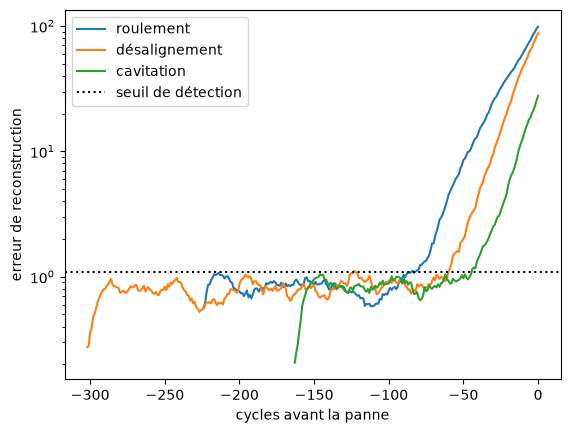

In [35]:
# Indicateur de santé de 3 pompes de validation (une par mode) : erreur de reconstruction vs cycles avant la panne
err_val = AE[K_RETENU][1]["val"]
seuil_det = np.percentile(AE[K_RETENU][1]["train"][NA["train"].rul.values > 150], 99)
d = NA["val"].assign(e=err_val)
mode_pompe = d.groupby("pompe")["mode"].first()
for mo in range(3):
    g = d[d.pompe == mode_pompe[mode_pompe == mo].index[0]]
    plt.semilogy(-g.rul, g.e, label=NOMS[1 + mo])
plt.axhline(seuil_det, color="k", ls=":", label="seuil de détection")
plt.xlabel("cycles avant la panne"); plt.ylabel("erreur de reconstruction")
plt.legend()
sauver_fig("q3_indicateur_sante"); plt.show()

## Q4. Ajouter l'indicateur de santé ou les sorties du CNN au MLP de RUL

**MLP de référence** (jalon 1) : entrées = dernier cycle (8 capteurs normalisés + charge), couches 64 et 32, sortie sigmoïde, cible `min(RUL, 125)/125`, perte MSE.
**Variantes** : + indicateur de santé (log de l'erreur de reconstruction, standardisé), + probabilités du CNN (4 valeurs), + les deux. Chaque variante sur 2 graines ; métriques sur la validation : RMSE (RUL plafonnée) et score asymétrique.

*Précaution* : les probabilités du CNN sur le train sont **hors-pli** (validation croisée par pompe), car le CNN est trop sûr de lui sur les données qu'il a vues ; sinon le MLP lui ferait trop confiance.

In [36]:
def score_nasa(y, yhat):
    d = yhat - y
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

# --- indicateur de santé (log-erreur standardisée par les cycles sains du train)
err = AE[K_RETENU][1]
log_e = {s: np.log(err[s] + 1e-8) for s in err}
ref = log_e["train"][NA["train"].rul.values > 150]
HI = {s: ((log_e[s] - ref.mean()) / ref.std()).astype("float32")[:, None] for s in log_e}

# --- probabilités du CNN : hors-pli sur le train, modèle complet sur val/test
P = np.zeros((len(SPEC["train"]), 4), "float32")
for tr, te in GroupKFold(3).split(SPEC["train"], groups=A["pompe_train"]):
    P[te] = entrainer_cnn(SEUIL_RETENU, SEED, idx=tr).predict(SPEC["train"][te], verbose=0)
PCNN = {"train": P, "val": cnn.predict(SPEC["val"], verbose=0), "test": cnn.predict(SPEC["test"], verbose=0)}

BASE = {s: NA[s][FEAT].values.astype("float32") for s in NA}
def entrees(variante, s):
    parts = [BASE[s]] + ([HI[s]] if "HI" in variante else []) + ([PCNN[s]] if "CNN" in variante else [])
    return np.hstack(parts)

YR = {s: np.minimum(NA[s].rul.values, RUL_MAX).astype("float32") / RUL_MAX for s in ("train", "val")}

def entrainer_mlp(variante, seed):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva = entrees(variante, "train"), entrees(variante, "val")
    m = keras.Sequential([layers.Input((Xtr.shape[1],)), layers.Dense(64, activation="relu"),
                          layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])
    m.compile("adam", "mse")
    m.fit(Xtr, YR["train"], validation_data=(Xva, YR["val"]), epochs=40, batch_size=256, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m

def metriques_val(m, variante):
    y = RUL_MAX * YR["val"]
    yh = RUL_MAX * m.predict(entrees(variante, "val"), verbose=0).ravel()
    return float(np.sqrt(np.mean((yh - y) ** 2))), score_nasa(y, yh)

In [37]:
VARIANTES = {"base": "", "+HI": "HI", "+CNN": "CNN", "+HI+CNN": "HI CNN"}
rows = []
for nom, v in VARIANTES.items():
    for seed in (0, 1):
        rmse, sc = metriques_val(entrainer_mlp(v, seed), v)
        rows.append(dict(variante=nom, seed=seed, rmse=rmse, score=sc))
        log("Q4", f"mlp_{nom}_seed{seed}", variante=nom, seed=seed, rmse=round(rmse, 2), score=round(sc, 0))
res4 = pd.DataFrame(rows)
tab4 = res4.groupby("variante", sort=False)[["rmse", "score"]].agg(["mean", "std"]).round(2)
print(tab4)
r0, r1 = tab4.loc["base", ("rmse", "mean")], tab4[("rmse", "mean")].drop("base").min()
print(f"\nRMSE base = {r0:.2f} | meilleure variante = {tab4[('rmse','mean')].drop('base').idxmin()} ({r1:.2f}) | cible finale : <= 23")

           rmse            score         
           mean   std       mean      std
variante                                 
base      19.00  0.09  104030.22  6845.51
+HI       18.63  0.05  103472.99  8377.11
+CNN      17.53  0.10   77681.96  4620.32
+HI+CNN   17.44  0.08   77691.38  4468.69

RMSE base = 19.00 | meilleure variante = +HI+CNN (17.44) | cible finale : <= 23


**Lecture.** Comparer le gain de RMSE à l'écart-type entre graines : un gain inférieur à l'écart-type n'est pas démontré. Les probabilités du CNN et l'indicateur de santé apportent surtout une information sur le **mode** et sur la **dégradation** que les huit capteurs agrégés contiennent déjà en partie ; le gain dépend donc de ce que le MLP de base manquait.

## Vérifications théoriques (calcul à la main, puis vérifié par le code)

**1. Résolution en fréquence.** Fenêtre de 62 points à 1000 Hz : Δf = fs / N = 1000 / 62 ≈ **16,1 Hz** par ligne ; le spectrogramme a 62/2 + 1 = **32 lignes** (0 à 500 Hz). Fréquence de rotation f_rot = tr/min / 60 ; défaut de roulement = 3,58 × f_rot ; ligne = f / Δf.

**2. Dimensions et paramètres du CNN** (entrée 32×32×1) :

| Couche | Sortie | Paramètres |
|---|---|---|
| Conv 3×3, 16 filtres | 32×32×16 | 3·3·1·16 + 16 = 160 |
| MaxPool 2×2 | 16×16×16 | 0 |
| Conv 3×3, 32 filtres | 16×16×32 | 3·3·16·32 + 32 = 4 640 |
| MaxPool 2×2 | 8×8×32 | 0 |
| Flatten | 2 048 | 0 |
| Dense 64 | 64 | 2048·64 + 64 = 131 136 |
| Dense 4 | 4 | 64·4 + 4 = 260 |
| **Total** | | **136 196** |

In [38]:
fs, N = 1000, 62
df_ = fs / N
print(f"résolution = {df_:.2f} Hz | lignes = {N//2 + 1}")
for type_, rpm in {"A": 1480, "B": 2960}.items():
    f_rot = rpm / 60
    f_def = 3.58 * f_rot
    print(f"type {type_} : f_rot = {f_rot:.2f} Hz | f_défaut = {f_def:.1f} Hz | ligne = {f_def/df_:.2f} (~ {round(f_def/df_)})")

assert cnn.count_params() == 160 + 4640 + 131136 + 260 == 136196
cnn.summary()

résolution = 16.13 Hz | lignes = 32
type A : f_rot = 24.67 Hz | f_défaut = 88.3 Hz | ligne = 5.48 (~ 5)
type B : f_rot = 49.33 Hz | f_défaut = 176.6 Hz | ligne = 10.95 (~ 11)


Model: "sequential_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_84 (Conv2D)              │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_84 (MaxPooling2D) │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_85 (Conv2D)              │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_85 (MaxPooling2D) │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_42 (Flatten)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_120 (Dense)               │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_121 (Dense)               │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 408,590 (1.56 MB)

 Trainable params: 136,196 (532.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 272,394 (1.04 MB)

## Test (à exécuter UNE seule fois, à la fin)
Mettre `EVAL_TEST = True` dans la première cellule, puis relancer **uniquement** cette cellule. Mesures par pompe, au dernier cycle observé : exactitude du mode sur les pompes à RUL finale ≤ 60, et RMSE / score de la RUL (meilleur MLP de la Q4).

In [39]:
if EVAL_TEST:
    pos = TA["test"].reset_index().groupby("pompe")["index"].last().loc[A["pompe_id_test"]].values
    # CNN : mode sur les pompes à <= 60 cycles de la panne
    pred_t = PCNN["test"].argmax(1)[pos]
    pr = A["rul_fin_test"] <= SEUIL_EVAL
    print("exactitude mode (pompes RUL <= 60) :", round(float((pred_t[pr] == 1 + A["mode_pompe_test"][pr]).mean()), 3), f"({pr.sum()} pompes)")
    # MLP de RUL : meilleure variante sur la validation
    v = VARIANTES[tab4[("rmse", "mean")].idxmin()]
    mlp_final = entrainer_mlp(v, SEED)
    y = np.minimum(A["rul_fin_test"], RUL_MAX)
    mlp_final.save("models/jalon2_mlp_final.keras")
    yh = RUL_MAX * mlp_final.predict(entrees(v, "test")[pos], verbose=0).ravel()
    print("RMSE test :", round(float(np.sqrt(np.mean((yh - y) ** 2))), 2), "| score :", round(score_nasa(y, yh), 0))
else:
    print("Test non évalué (EVAL_TEST = False).")

Test non évalué (EVAL_TEST = False).


## Page de décisions

**Résultats** : voir `tab1` (Q1), `q2` (Q2), `q3` (Q3), `tab4` (Q4) ; journal exporté ci-dessous. Écart à la cible : exactitude du mode (≥ 0,85) et RMSE (≤ 23) sont des cibles du système *final* ; on les compare et on explique l'écart à partir des tableaux.

**Règle d'étiquetage.** Seuil retenu = plus petit seuil équivalent au meilleur (à un écart-type). Raison : au-delà, on étiquette « défaut » des spectrogrammes encore indiscernables du sain ; en dessous de 60, la zone évaluée n'a plus d'exemples de défaut.

**Spectrogramme plutôt que signal brut.** Les défauts se signalent par des motifs en fréquence (raies de roulement, bande basse du désalignement, bloc haute fréquence de la cavitation) qui se lisent directement dans le spectrogramme ; la convolution 2D les détecte sans avoir à apprendre une transformée de Fourier à partir de 1000 points bruités.

**Indicateur non supervisé quand les pannes sont rares.** Il n'utilise que des cycles sains (abondants) et aucune étiquette de panne : il reste utilisable pour un nouveau modèle de pompe (type B, 10 pompes seulement) et détecte des dégradations de type inconnu, ce qu'un classifieur supervisé ne peut pas faire.

**Limites.** Données simulées ; validation de 15 pompes (variance élevée) ; une graine pour l'indicateur de santé ; type B non étudié ici.

In [40]:
pd.DataFrame(JOURNAL).to_csv("journal_jalon2.csv", index=False)
print(len(JOURNAL), "essais journalisés -> journal_jalon2.csv")

20 essais journalisés -> journal_jalon2.csv
